# Personality Test Score Analyzer

This notebook simulates random people taking your personality test, reports the distribution of all 27 types and the three individual trait groups, and displays all four charts together.

## Expected question format

Save your question array as `questions.json` in the same folder as this notebook. Each question should look roughly like:

```json
{
  "id": "q1",
  "text": "Question text",
  "type": "normal",
  "answers": [
    {
      "text": "Answer A",
      "score": {"H": 1, "S": 0, "L": -1, "P": 0, "R": 0, "A": 0, "E": 0, "W": 1, "D": 1},
      "followup": "q1-a-followup"
    }
  ]
}
```

The notebook assumes:
- Normal questions appear in the order they occur in the JSON array.
- Selecting an answer may trigger its `followup` question.
- Follow-ups can themselves trigger further follow-ups.
- Each follow-up ID points to exactly one question.
- Missing trait scores are treated as zero.
- Every answer is equally likely in the random simulation.

**Scoring assumption:** For each trait, the available maximum on a simulated path is calculated by adding the highest answer score for that trait at each question actually encountered. This handles branching better than treating every possible follow-up as if everyone sees it. The notebook also reports a simple inventory maximum across all questions, but that number is not necessarily achievable on one path.

The type calculation below compares each trait's percentage of its path-specific maximum. You can change the scoring function if your production test uses a different denominator or handles negative scores differently.

## 1. Settings and load the questions

Change the filename and number of simulations if needed. 100,000 simulations is a reasonable starting point; increase it for more stable estimates.

In [32]:
import json
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ----------------------------
# SETTINGS
# ----------------------------
QUESTION_FILE = "questions.json"
SIMULATIONS = 100_000
RANDOM_SEED = 42

TRAITS = ["H", "S", "L", "P", "R", "A", "E", "W", "D"]
GROUPS = [
    ["H", "S", "L"],
    ["P", "R", "A"],
    ["E", "W", "D"]
]
GROUP_NAMES = ["Group 1 (H / S / L)", "Group 2 (P / R / A)", "Group 3 (E / W / D)"]

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

with open(QUESTION_FILE, "r", encoding="utf-8") as f:
    questions = json.load(f)

# Validate IDs and build a lookup table.
question_map = {}
for q in questions:
    qid = q.get("id")
    if not qid:
        raise ValueError("Every question must have an 'id'.")
    if qid in question_map:
        raise ValueError(f"Duplicate question ID: {qid}")
    if not q.get("answers"):
        raise ValueError(f"Question {qid} has no answers.")
    question_map[qid] = q

normal_questions = [q for q in questions if q.get("type") != "followup"]
followup_questions = [q for q in questions if q.get("type") == "followup"]

print(f"Questions loaded: {len(questions):,}")
print(f"Normal questions: {len(normal_questions):,}")
print(f"Follow-up questions: {len(followup_questions):,}")
print(f"Simulations planned: {SIMULATIONS:,}")

if not normal_questions:
    raise ValueError("No questions with type='normal' were found.")

# Check that every referenced follow-up exists.
missing_followups = sorted({
    answer["followup"]
    for q in questions
    for answer in q["answers"]
    if answer.get("followup") and answer["followup"] not in question_map
})
if missing_followups:
    raise ValueError(f"Follow-up IDs not found in the question list: {missing_followups}")

# This notebook processes normal questions in their JSON-array order.
print("\nFirst normal question:", normal_questions[0]["id"])


Questions loaded: 129
Normal questions: 87
Follow-up questions: 42
Simulations planned: 100,000

First normal question: q1


## 2. Simulation and scoring

Each run:
1. Visits every normal question in array order.
2. Randomly chooses one answer.
3. Applies its score.
4. Immediately processes any follow-up chain caused by that answer.
5. Records how many questions were actually answered and the maximum available score for each trait along that path.

For a given question and trait, the path-specific maximum adds the highest score offered by any answer to that question. This is a useful measure of available scoring opportunity, but if answer choices lead to different follow-ups, the denominator is conditional on the randomly selected path.

In [ ]:
def score_for_answer(answer, trait):
    return answer.get("score", {}).get(trait, 0) or 0


def apply_question(question, scores, path_max, rng):
    """Answer one question, then recursively process its selected follow-up chain."""
    answers = question["answers"]
    answer = rng.choice(answers)

    for trait in TRAITS:
        scores[trait] += score_for_answer(answer, trait)
        # Maximum score available for this trait at this encountered question.
        path_max[trait] += max(score_for_answer(a, trait) for a in answers)

    count = 1

    followup_id = answer.get("followup")
    if followup_id:
        count += apply_question(
            question_map[followup_id], scores, path_max, rng
        )

    return count


def simulate_one(rng):
    scores = {trait: 0 for trait in TRAITS}
    path_max = {trait: 0 for trait in TRAITS}
    answered_count = 0

    for question in normal_questions:
        answered_count += apply_question(question, scores, path_max, rng)

    # Convert raw scores to percentages of the maximum available on this path.
    # A zero or negative denominator is treated as undefined (NaN).
    percentages = {}
    adjs = {}
    for trait in TRAITS:
        denominator = path_max[trait]
        percentages[trait] = (
            100 * scores[trait] / denominator
            if denominator > 0 else np.nan
        )
        if trait in ("S","H","L"):
            adjs[trait] = percentages[trait]
        elif trait in ("R","A","P"):
            adjs[trait] = percentages[trait] + scores[trait] + (1 if trait == "A" else 0)
        elif trait == "E":
            adjs[trait] = percentages[trait] + 2
        else:    
            adjs[trait] = percentages[trait]

    return {
        "scores": scores,
        "path_max": path_max,
        "percentages": percentages,
        "question_count": answered_count,
        "adjs": adjs
    }


def determine_type(percentages):
    """Choose the highest percentage in each of the three trait groups."""
    letters = []
    for group in GROUPS:
        valid = [(trait, percentages[trait]) for trait in group
                 if not np.isnan(percentages[trait])]
        if not valid:
            letters.append("?")
        else:
            # Ties are resolved by the order in GROUPS.
            letters.append(max(valid, key=lambda item: item[1])[0])
    return "".join(letters)


# Run the simulation.
rng = random.Random(RANDOM_SEED)
results = []

for _ in range(SIMULATIONS):
    run = simulate_one(rng)
    row = {
        "type": determine_type(run["adjs"]),
        "question_count": run["question_count"]
    }
    for trait in TRAITS:
        row[f"score_{trait}"] = run["scores"][trait]
        row[f"max_{trait}"] = run["path_max"][trait]
        row[f"pct_{trait}"] = run["percentages"][trait]
    results.append(row)

df = pd.DataFrame(results)
print(f"Completed {len(df):,} simulations.")


Completed 100,000 simulations.


## 3. Question counts and maximum-score report

This section prints:
- The number of questions in the file, split into normal and follow-up questions.
- The average, minimum, and maximum number of questions answered per simulated test.
- The maximum-score inventory for each trait across every question in the file.
- The average, minimum, and maximum path-specific maximum available score for each trait.

The inventory maximum is a simple sum of the highest answer score at every question in the file. It may overstate what one test-taker can encounter because many follow-ups are mutually exclusive.

In [125]:
print("QUESTION COUNTS")
print("----------------")
print(f"Questions in JSON file: {len(questions):,}")
print(f"Normal questions:       {len(normal_questions):,}")
print(f"Follow-up questions:    {len(followup_questions):,}")
print(f"Average answered/run:   {df['question_count'].mean():.2f}")
print(f"Minimum answered/run:   {df['question_count'].min():,}")
print(f"Maximum answered/run:   {df['question_count'].max():,}")

# Sum of each question's highest answer score for each trait.
# This is an all-questions inventory figure, not necessarily a reachable path maximum.
inventory_max = {
    trait: sum(
        max(score_for_answer(answer, trait) for answer in q["answers"])
        for q in questions
    )
    for trait in TRAITS
}

max_score_report = pd.DataFrame({
    "Trait": TRAITS,
    "All-question inventory max": [inventory_max[t] for t in TRAITS],
    "Avg path max": [df[f"max_{t}"].mean() for t in TRAITS],
    "Min path max": [df[f"max_{t}"].min() for t in TRAITS],
    "Max path max": [df[f"max_{t}"].max() for t in TRAITS],
    "Avg actual score": [df[f"score_{t}"].mean() for t in TRAITS],
    "Avg score % of path max": [df[f"pct_{t}"].mean() for t in TRAITS],
})

print("\nMAXIMUM SCORE BY TRAIT")
print("----------------------")
display(max_score_report.round(2))


QUESTION COUNTS
----------------
Questions in JSON file: 129
Normal questions:       87
Follow-up questions:    42
Average answered/run:   87.00
Minimum answered/run:   87
Maximum answered/run:   87

MAXIMUM SCORE BY TRAIT
----------------------


,Trait,All-question inventory max,Avg path max,Min path max,Max path max,Avg actual score,Avg score % of path max
0,H,257,180.0,180,180,50.10,27.84
1,S,234,195.0,195,195,58.36,29.93
2,L,201,173.0,173,173,48.17,27.84
3,P,280,197.0,197,197,56.34,28.60
4,R,221,182.0,182,182,52.40,28.79
5,A,220,154.0,154,154,44.37,28.81
6,E,231,166.0,166,166,45.91,27.66
7,W,177,145.0,145,145,41.47,28.60
8,D,200,146.0,146,146,42.38,29.03


## 4. Personality type and trait percentages

The tables below show the percentage of simulated test-takers who receive each type or win each individual trait group. Types that do not occur are still shown with 0%.

If every type were equally likely, each of the 27 types would occur about 3.70% of the time. Each trait in an individual three-trait group would occur about 33.33% of the time.

In [126]:
ALL_TYPES = [
    a + b + c
    for a in GROUPS[0]
    for b in GROUPS[1]
    for c in GROUPS[2]
]

type_counts = df["type"].value_counts().reindex(ALL_TYPES, fill_value=0)
type_percentages = type_counts / len(df) * 100

print("PERSONALITY TYPE DISTRIBUTION")
print("-----------------------------")
type_report = pd.DataFrame({
    "Count": type_counts,
    "Percent": type_percentages
}).sort_values("Percent", ascending=False)
display(type_report.round(2))

for group_name, group in zip(GROUP_NAMES, GROUPS):
    winners = []
    for _, row in df.iterrows():
        vals = {t: row[f"pct_{t}"] for t in group}
        valid = [(t, v) for t, v in vals.items() if pd.notna(v)]
        winners.append(max(valid, key=lambda x: x[1])[0] if valid else "?")

    counts = pd.Series(winners).value_counts().reindex(group, fill_value=0)
    percentages = counts / len(df) * 100

    print(f"\n{group_name}")
    print("-" * len(group_name))
    display(pd.DataFrame({
        "Count": counts,
        "Percent": percentages
    }).round(2))


PERSONALITY TYPE DISTRIBUTION
-----------------------------


,Count,Percent
type,,
SRE,6243,6.24
SPD,5261,5.26
SPE,5252,5.25
SPW,5031,5.03
LPW,4737,4.74
HPD,4673,4.67
LPD,4474,4.47
LPE,4315,4.32
SRD,4279,4.28



Group 1 (H / S / L)
-------------------


,Count,Percent
H,30010,30.01
S,39373,39.37
L,30617,30.62



Group 2 (P / R / A)
-------------------


,Count,Percent
P,31623,31.62
R,34298,34.30
A,34079,34.08



Group 3 (E / W / D)
-------------------


,Count,Percent
E,29502,29.50
W,35148,35.15
D,35350,35.35


## 5. All four charts together

The first chart shows all 27 types. The other three show the winning trait in each group. The dashed horizontal lines mark an even distribution: 3.70% for the 27 types and 33.33% for each three-trait group.

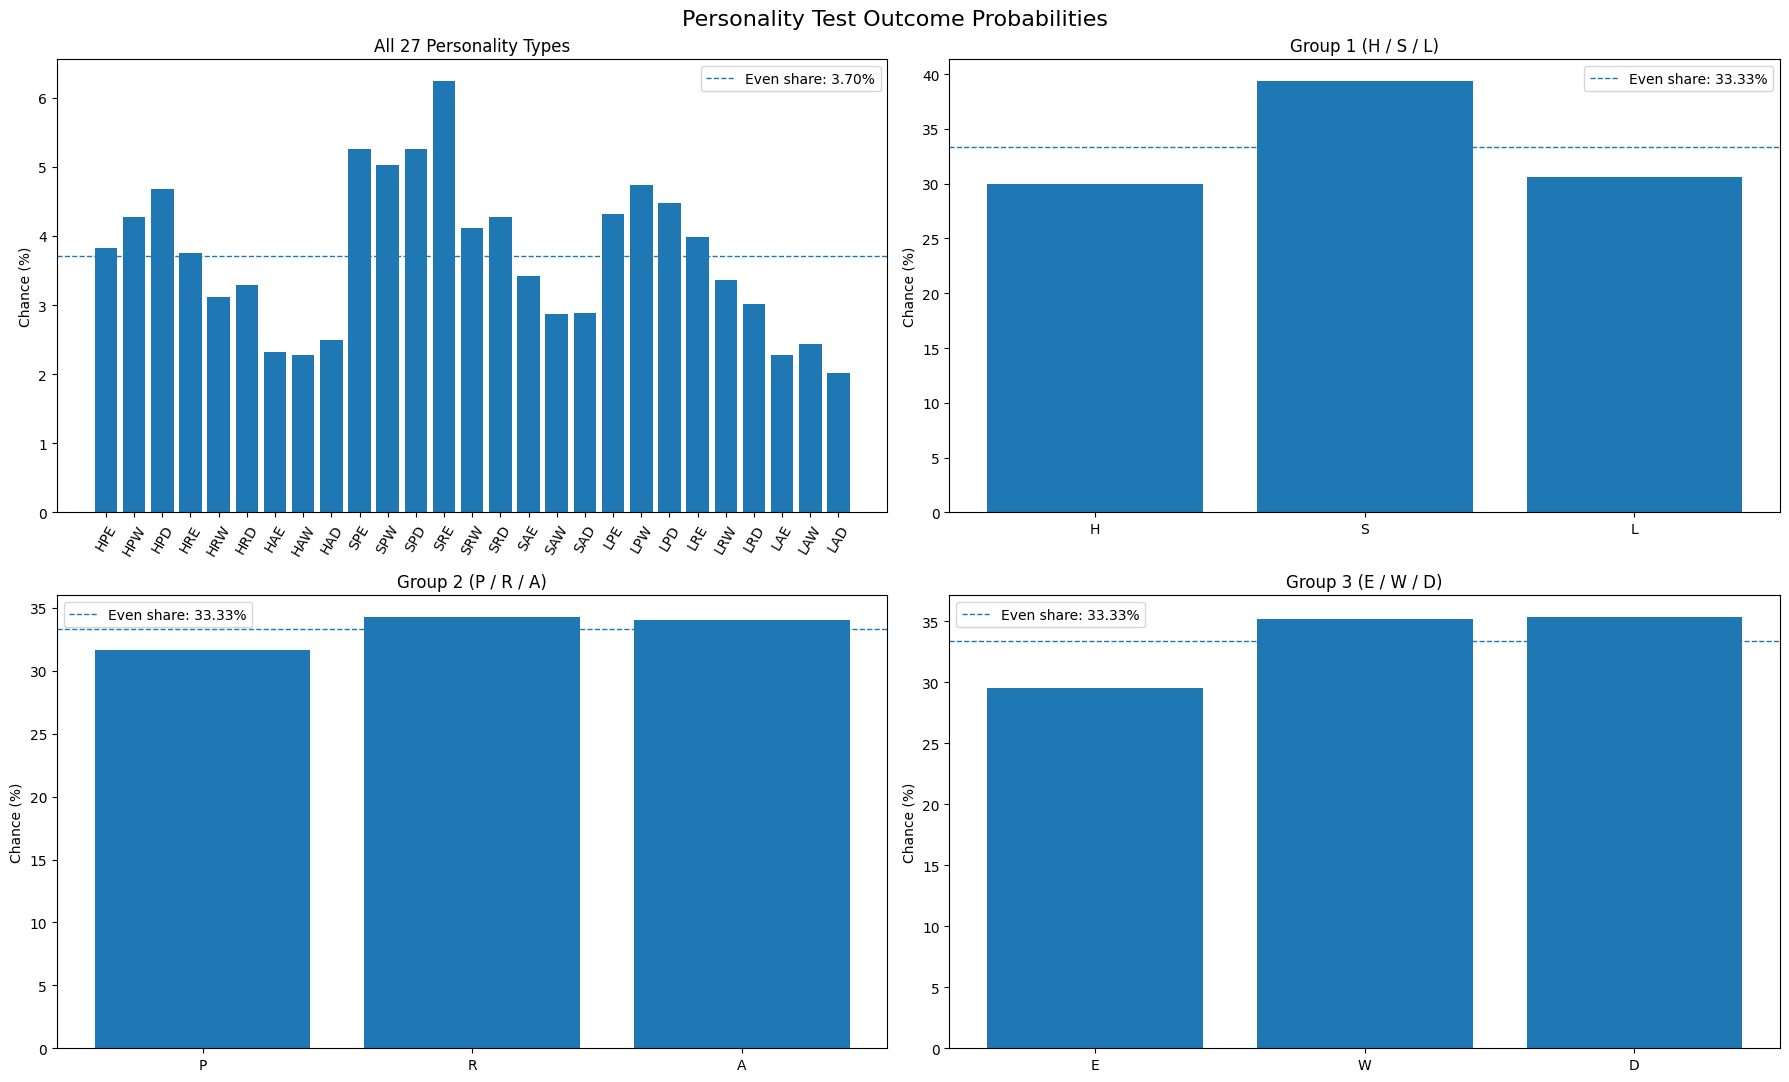

In [127]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))

# 27 personality types
axes[0, 0].bar(ALL_TYPES, type_percentages.reindex(ALL_TYPES).values)
axes[0, 0].axhline(100 / 27, linestyle="--", linewidth=1,
                   label=f"Even share: {100/27:.2f}%")
axes[0, 0].set_title("All 27 Personality Types")
axes[0, 0].set_ylabel("Chance (%)")
axes[0, 0].tick_params(axis="x", rotation=60)
axes[0, 0].legend()

# Individual trait groups
for ax, group, group_name in zip(
    [axes[0, 1], axes[1, 0], axes[1, 1]],
    GROUPS,
    GROUP_NAMES
):
    winner_list = []
    for _, row in df.iterrows():
        vals = [(t, row[f"pct_{t}"]) for t in group
                if pd.notna(row[f"pct_{t}"])]
        winner_list.append(max(vals, key=lambda x: x[1])[0] if vals else "?")

    counts = pd.Series(winner_list).value_counts().reindex(group, fill_value=0)
    percentages = counts / len(df) * 100

    ax.bar(group, percentages.values)
    ax.axhline(100 / 3, linestyle="--", linewidth=1,
               label=f"Even share: {100/3:.2f}%")
    ax.set_title(group_name)
    ax.set_ylabel("Chance (%)")
    ax.set_ylim(bottom=0)
    ax.legend()

fig.suptitle("Personality Test Outcome Probabilities", fontsize=16)
plt.tight_layout()
plt.show()


## 6. Optional: average trait percentages

This table is different from the winner percentages. It shows the average normalized score each trait receives, whether or not it wins its group. A trait can have a high average score but still lose frequently if another trait in its group is even higher.

In [128]:
average_trait_report = pd.DataFrame({
    "Trait": TRAITS,
    "Average raw score": [df[f"score_{t}"].mean() for t in TRAITS],
    "Average path maximum": [df[f"max_{t}"].mean() for t in TRAITS],
    "Average normalized score (%)": [df[f"pct_{t}"].mean() for t in TRAITS],
    "Median normalized score (%)": [df[f"pct_{t}"].median() for t in TRAITS],
})

display(average_trait_report.round(2))


,Trait,Average raw score,Average path maximum,Average normalized score (%),Median normalized score (%)
0,H,50.10,180.0,27.84,27.78
1,S,58.36,195.0,29.93,29.74
2,L,48.17,173.0,27.84,27.75
3,P,56.34,197.0,28.60,28.43
4,R,52.40,182.0,28.79,28.57
5,A,44.37,154.0,28.81,28.57
6,E,45.91,166.0,27.66,27.11
7,W,41.47,145.0,28.60,28.28
8,D,42.38,146.0,29.03,28.77


## Notes and limitations

- This estimates probabilities under **uniformly random answer choices**. Real people will not necessarily choose every answer equally often.
- The simulation is an estimate, not an exhaustive enumeration. Increasing `SIMULATIONS` reduces random sampling noise.
- The code assumes every normal question is asked, in the order it appears in the JSON array. Follow-ups are asked immediately after the answer that triggers them.
- If your real test skips normal questions, has other routing rules, or uses a different denominator, update `simulate_one()` accordingly.
- Ties are currently broken by the first trait listed in the relevant group. If your actual test handles ties differently, change `determine_type()`.
- The example percentage calculation assumes a positive path maximum. If your scoring formula uses a different denominator or permits negative normalized percentages, replace that section in `simulate_one()`.
- Your sample in the chat contains a few malformed JSON fragments (for example, missing numeric values and missing closing braces). The actual `questions.json` file must be valid JSON before this notebook can load it.
